# So sánh các mô hình PM2.5 ngày trên lưới 0,05°

| Nhóm | Mô hình | Thư mục |
|---|---|---|
| Global | LightGBM tune bằng Optuna (nested CV): `Global` (chỉ x) và `Global -st` (+ biến không gian/thời gian) | `global_model/{original,st}/` |
| Local | GTW-RF, GTW-XGBoost, GTW-LightGBM (Li et al. 2024) | `local_model/gtw_tree/` |
| Local | ASTMNN (Wang et al. 2024) | `local_model/ASTMNN/` |

Mọi mô hình dùng **cùng 5 fold theo ô** (`data/cv_folds.csv`), nên mỗi ô–ngày có một dự đoán ngoài mẫu cho mỗi mô hình. Các mục dưới chỉ dùng những ô–ngày mà **mọi** mô hình được so đều đã có dự đoán, nên vẫn so sánh công bằng khi một mô hình chưa chạy xong.

Chi tiết riêng của từng mô hình nằm trong notebook trong thư mục của mô hình đó: tham số Optuna, lưới λ × N0, lưới w × t, đường học, độ quan trọng biến cục bộ.

## 0. Thiết lập

In [1]:
%matplotlib inline
import json, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook'); plt.rcParams['figure.dpi'] = 110
MODEL_DIR = Path.cwd()                        # pm25_map/model
sys.path.insert(0, str(MODEL_DIR))
import _data as D, _results as R
frame = D.build_frame(); cells = R.cell_table(frame)
preds = R.load_all()
for k, v in preds.items():
    print(f'{k:28s}: {v.pred.notna().sum():>7,} dự đoán · fold {sorted(v.outer_fold.unique().tolist())}')
NAMES = list(preds)
J = R.joined(preds, frame, NAMES) if NAMES else None
print('\nô–ngày chung của mọi mô hình:', 0 if J is None else f'{len(J):,} ({J.cell_id.nunique()} ô, fold {sorted(J.outer_fold.unique())})')

Global                      :  46,377 dự đoán · fold [0, 1, 2, 3, 4]
Global -st                  :  46,377 dự đoán · fold [0, 1, 2, 3, 4]
GTW-RF                      :  46,374 dự đoán · fold [0, 1, 2, 3, 4]
GTW-XGBoost                 :  46,374 dự đoán · fold [0, 1, 2, 3, 4]
GTW-LightGBM                :  46,374 dự đoán · fold [0, 1, 2, 3, 4]
ASTMNN                      :  46,377 dự đoán · fold [0, 1, 2, 3, 4]

ô–ngày chung của mọi mô hình: 46,374 (80 ô, fold [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)])


## 1. Bảng tổng hợp (~ Supplementary Table 1 của Li et al. 2024)
`R2` = 1 − SSE/SST; `R2_paper` = bình phương hệ số tương quan, đúng công thức của Li et al. 2024; `RPE` = RMSE / TB quan trắc (%). `R2_fold_mean ± sd` cho biết độ ổn định giữa các fold.

In [2]:
table = R.metrics_table(J, NAMES).sort_values('RMSE')
(table.style
 .format({'N': '{:,.0f}', 'R2': '{:.3f}', 'R2_paper': '{:.3f}', 'RMSE': '{:.2f}', 'MAE': '{:.2f}', 'RPE': '{:.1f}',
          'slope': '{:.2f}', 'bias': '{:+.2f}', 'R2_fold_mean': '{:.3f}', 'R2_fold_sd': '{:.3f}'})
 .background_gradient(subset=['R2', 'R2_paper'], cmap='RdYlGn')
 .background_gradient(subset=['RMSE', 'RPE'], cmap='RdYlGn_r'))

,N,R2,R2_paper,RMSE,MAE,RPE,slope,bias,R2_fold_mean,R2_fold_sd
model,,,,,,,,,,
Global -st,"46,374",0.570,0.574,14.94,9.84,57.5,0.62,-0.35,0.567,0.103
GTW-RF,"46,374",0.528,0.546,15.66,10.27,60.2,0.64,+0.29,0.513,0.130
GTW-LightGBM,"46,374",0.524,0.537,15.73,10.50,60.5,0.62,+0.08,0.512,0.123
Global,"46,374",0.488,0.492,16.32,11.01,62.7,0.54,-0.19,0.466,0.105
GTW-XGBoost,"46,374",0.473,0.506,16.55,10.83,63.7,0.64,+0.15,0.459,0.118
ASTMNN,"46,374",0.467,0.487,16.64,10.82,64.0,0.58,+0.21,0.467,0.053


In [3]:
REF = 'Global' if 'Global' in NAMES else None            # mốc: cùng 15 biến x với các mô hình local
LOCALS = [n for n in NAMES if n.startswith(('GTW', 'ASTMNN'))]
PAIRS = [(r, l) for r in ('Global', 'Global -st') if r in NAMES for l in LOCALS]
print('Global ↔ từng mô hình local (cùng tập ô–ngày):')
for g, l in PAIRS:
    a, b = table.loc[g], table.loc[l]
    print(f'  {g:26s} → {l:14s}: R² {a.R2:.3f} → {b.R2:.3f} ({b.R2 - a.R2:+.3f}) · '
          f'RMSE {a.RMSE:.2f} → {b.RMSE:.2f} ({100 * (b.RMSE / a.RMSE - 1):+.1f}%)')

Global ↔ từng mô hình local (cùng tập ô–ngày):
  Global                     → GTW-RF        : R² 0.488 → 0.528 (+0.040) · RMSE 16.32 → 15.66 (-4.0%)
  Global                     → GTW-XGBoost   : R² 0.488 → 0.473 (-0.015) · RMSE 16.32 → 16.55 (+1.4%)
  Global                     → GTW-LightGBM  : R² 0.488 → 0.524 (+0.036) · RMSE 16.32 → 15.73 (-3.6%)
  Global                     → ASTMNN        : R² 0.488 → 0.467 (-0.020) · RMSE 16.32 → 16.64 (+2.0%)
  Global -st                 → GTW-RF        : R² 0.570 → 0.528 (-0.042) · RMSE 14.94 → 15.66 (+4.8%)
  Global -st                 → GTW-XGBoost   : R² 0.570 → 0.473 (-0.098) · RMSE 14.94 → 16.55 (+10.8%)
  Global -st                 → GTW-LightGBM  : R² 0.570 → 0.524 (-0.047) · RMSE 14.94 → 15.73 (+5.3%)
  Global -st                 → ASTMNN        : R² 0.570 → 0.467 (-0.103) · RMSE 14.94 → 16.64 (+11.3%)


## 2. Scatter quan trắc ↔ ước lượng (~ Fig. 1 của Li et al. 2024)
Hexbin thang log, đường 1:1 (đứt) và đường hồi quy (đỏ). Độ dốc < 1 nghĩa là mô hình kéo giá trị cao xuống, điểm yếu quen thuộc của mô hình global.

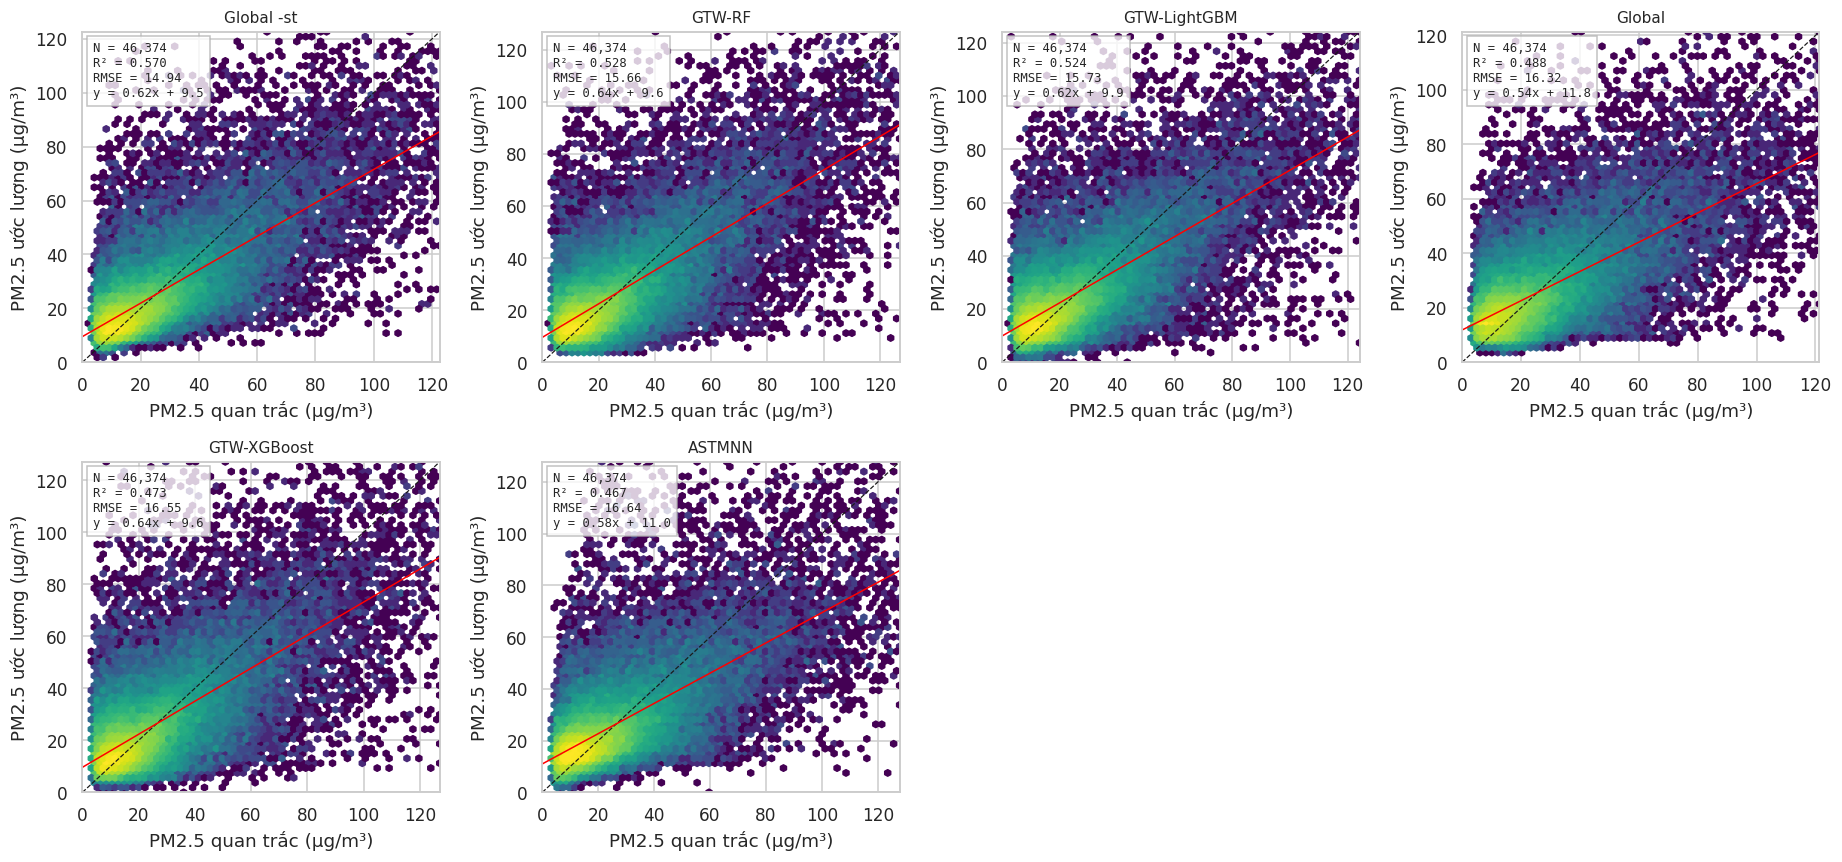

In [4]:
ncols = 4; nrows = -(-len(NAMES) // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 4.0 * nrows), squeeze=False)
for ax, n in zip(axes.ravel(), table.index):
    R.density(ax, J[D.PM].values, J[n].values, n)
for ax in axes.ravel()[len(NAMES):]: ax.set_axis_off()
plt.tight_layout(); plt.show()

## 3. Hiệu năng từng ô (~ Fig. 2 của Li et al. 2024)
RMSE theo ngày của từng ô (≥ 30 ngày). Hàng dưới: chênh RMSE so với mốc global (xanh = tốt hơn mốc), có ghi tỉ lệ ô tốt hơn.

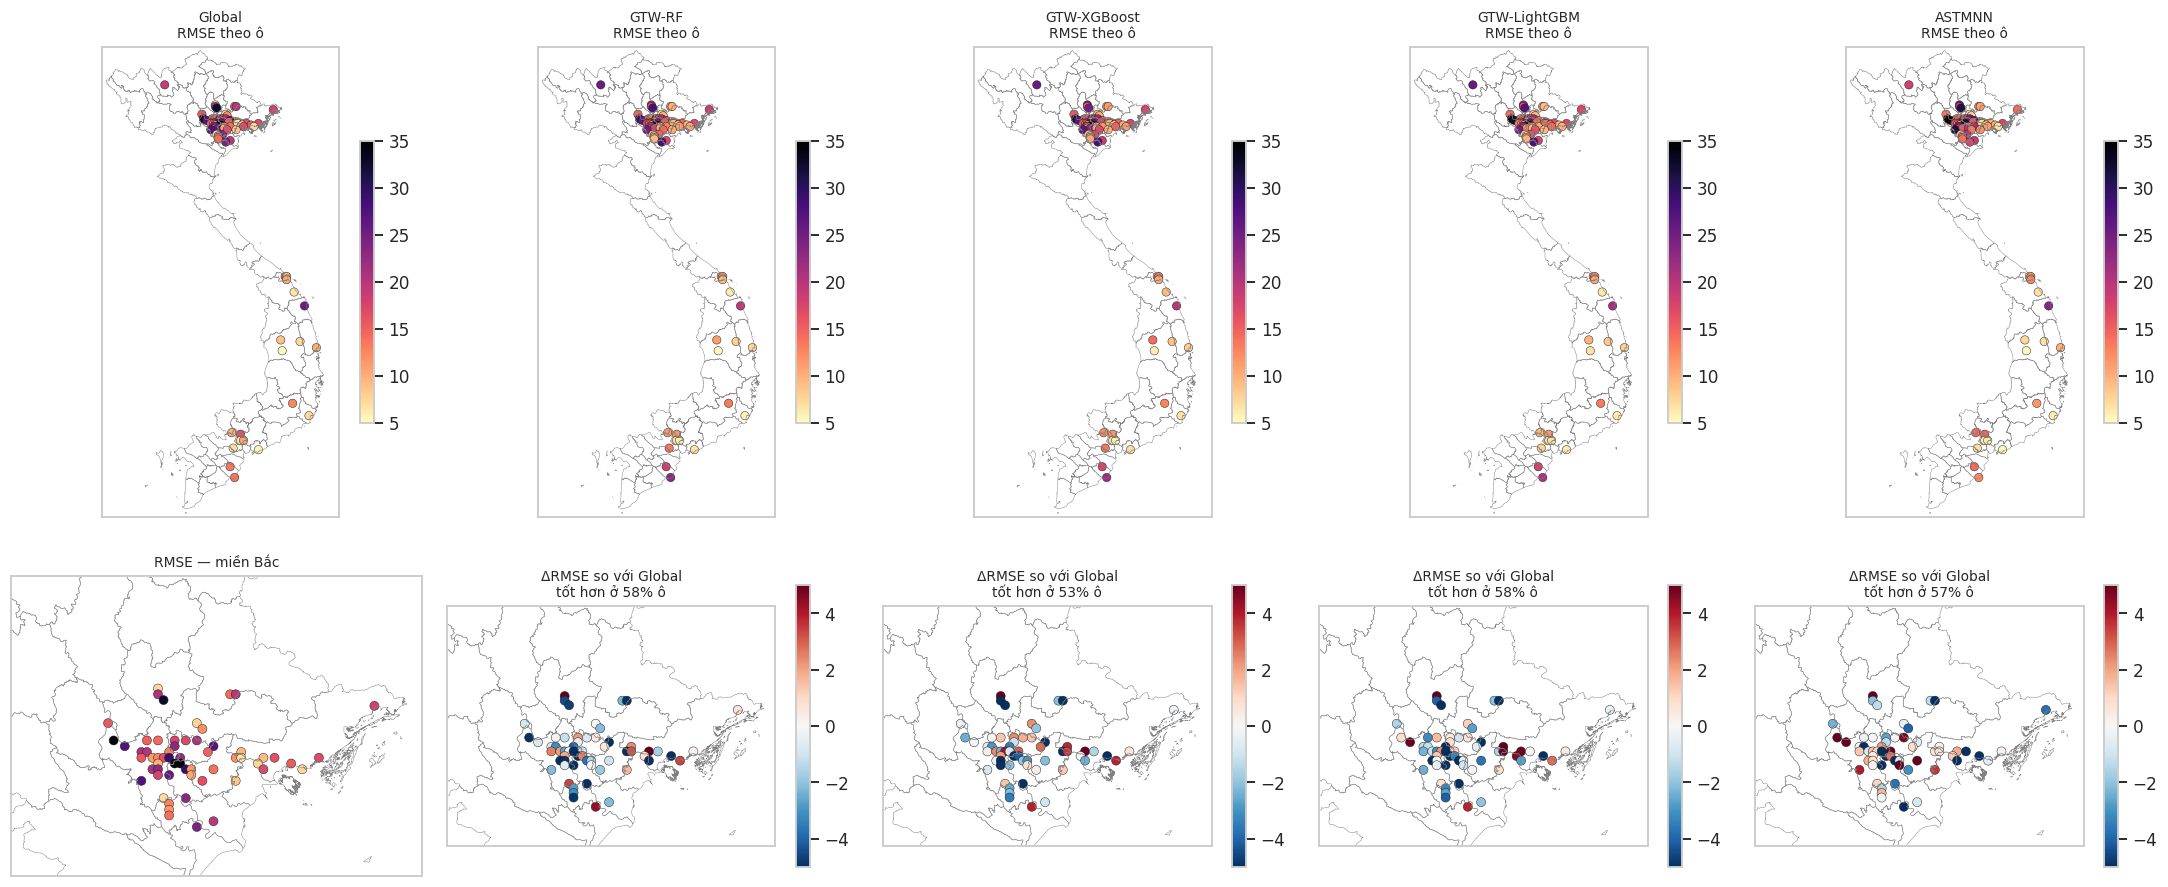

In [5]:
show = [n for n in (REF, *[l for _, l in PAIRS]) if n]
show = list(dict.fromkeys(show))
if show:
    pc = {n: R.per_cell(J, n, cells) for n in show}
    fig, axes = plt.subplots(2, len(show), figsize=(4.0 * len(show), 9), squeeze=False)
    for j, n in enumerate(show):
        c = pc[n]
        ax = axes[0, j]; R.vn_axes(ax)
        sc = ax.scatter(c.lon, c.lat, c=c.RMSE.astype(float), cmap='magma_r', vmin=5, vmax=35, s=30, edgecolor='k', lw=0.3)
        ax.set_title(f'{n}\nRMSE theo ô', fontsize=9); plt.colorbar(sc, ax=ax, shrink=0.6)
        ax = axes[1, j]; R.vn_axes(ax, 'north')
        if REF and n != REF:
            d = (c.RMSE - pc[REF].RMSE).astype(float).dropna()
            sc = ax.scatter(c.loc[d.index, 'lon'], c.loc[d.index, 'lat'], c=d, cmap='RdBu_r', vmin=-5, vmax=5, s=35, edgecolor='k', lw=0.3)
            ax.set_title(f'ΔRMSE so với {REF}\ntốt hơn ở {(d < 0).mean() * 100:.0f}% ô', fontsize=9); plt.colorbar(sc, ax=ax, shrink=0.6)
        else:
            sc = ax.scatter(c.lon, c.lat, c=c.RMSE.astype(float), cmap='magma_r', vmin=5, vmax=35, s=35, edgecolor='k', lw=0.3)
            ax.set_title('RMSE — miền Bắc', fontsize=9)
    plt.tight_layout(); plt.show()

## 4. Theo vùng, mùa và năm
Năm 2026 đáng chú ý: CAMS lấy từ sản phẩm *forecast* (0,4°), khác EAC4 (0,75°) của 2020–2025.

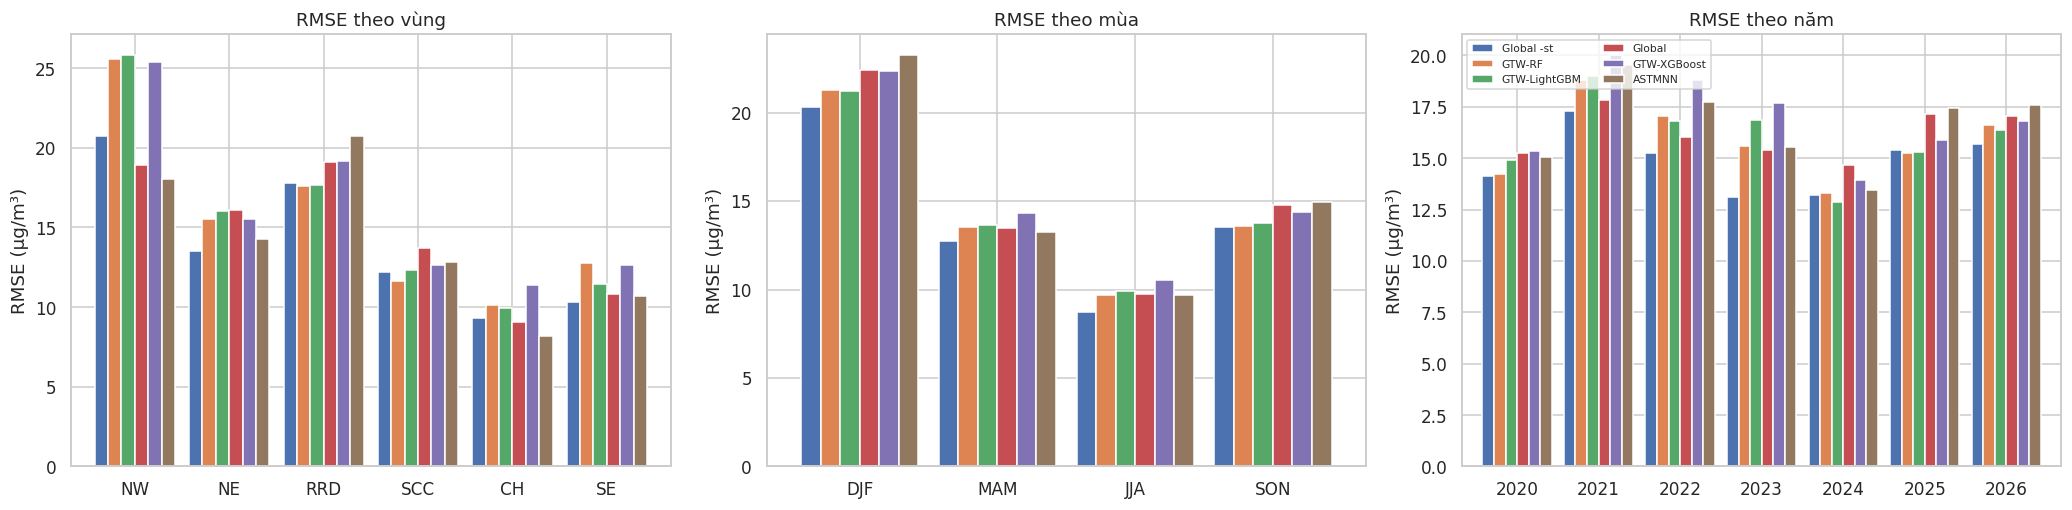

In [6]:
def strat(by, order=None):
    t = pd.DataFrame({n: J.groupby(by).apply(lambda g: D.metrics(g[D.PM], g[n])['RMSE'] if len(g) >= 100 else np.nan)
                      for n in table.index})
    return t.reindex([o for o in order if o in t.index]) if order else t

fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
for ax, (by, order, title) in zip(axes, (('region', D.REGION_ORDER, 'vùng'), ('season', ['DJF', 'MAM', 'JJA', 'SON'], 'mùa'), ('year', None, 'năm'))):
    strat(by, order).plot.bar(ax=ax, width=0.85, legend=(by == 'year'))
    ax.set_title(f'RMSE theo {title}'); ax.set_ylabel('RMSE (µg/m³)'); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=0)
axes[2].legend(fontsize=7, ncol=2, loc='upper left')
plt.tight_layout(); plt.show()

## 5. Chuỗi thời gian vài ô
Quan trắc so với mốc global và hai mô hình local tốt nhất, ở ô có nhiều ngày nhất của miền Bắc và miền Nam, trong 150 ngày cuối có dữ liệu.

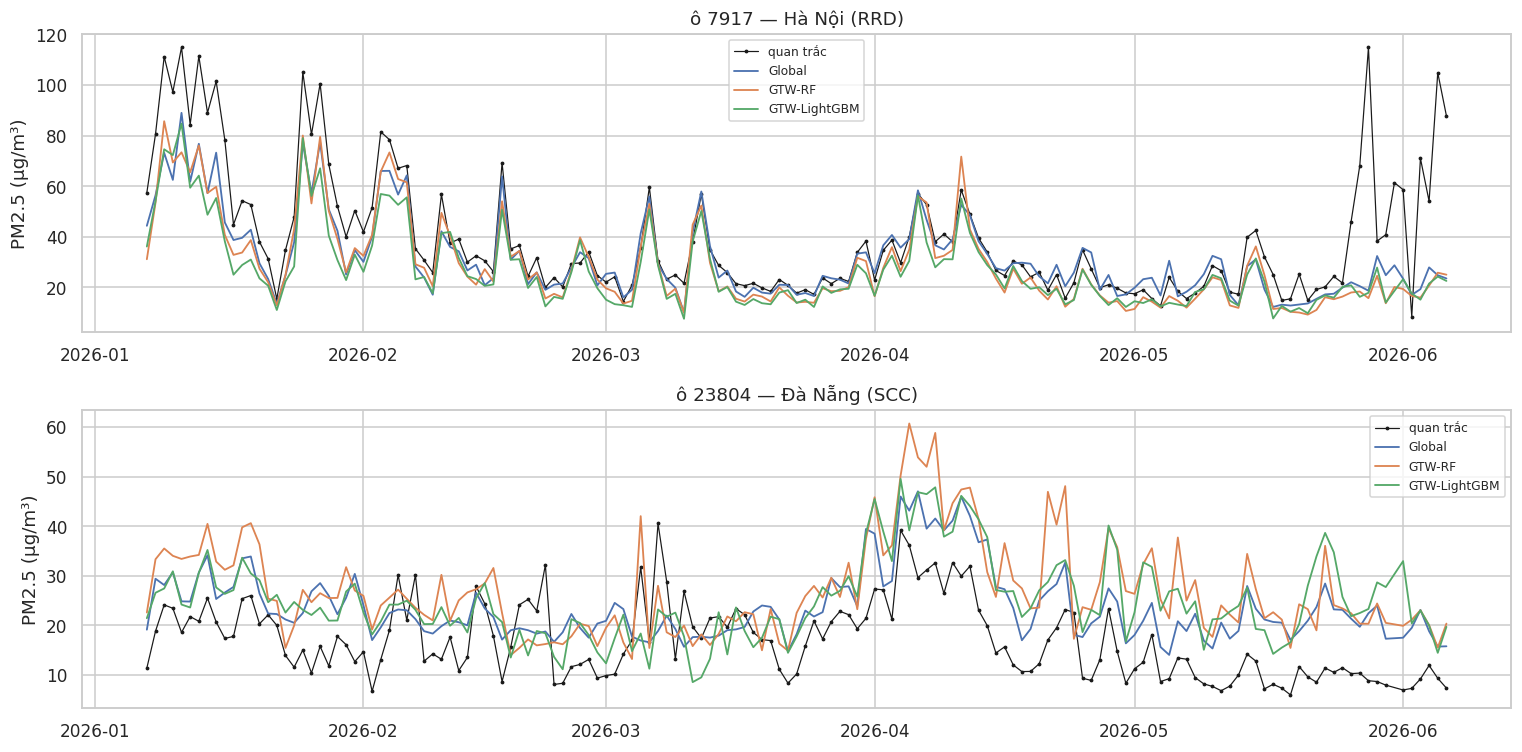

In [7]:
locals_ = [n for n in table.index if n.startswith(('GTW', 'ASTMNN'))][:2]
cand = [n for n in (REF, *locals_) if n]
picks = [J[J.region.isin(['RRD', 'NE'])].cell_id.value_counts().index[0],
         J[J.region.isin(['SE', 'SCC', 'CH'])].cell_id.value_counts().index[0]]
fig, axes = plt.subplots(2, 1, figsize=(14, 7))
for ax, c in zip(axes, picks):
    g = J[J.cell_id == c].sort_values('date'); g = g[g.date >= g.date.max() - pd.Timedelta(days=150)]
    ax.plot(g.date, g[D.PM], 'k.-', lw=0.8, ms=3, label='quan trắc')
    for n in cand: ax.plot(g.date, g[n], lw=1.2, label=n)
    meta = cells.set_index('cell_id').loc[c]
    ax.set_title(f'ô {c} — {meta.province} ({meta.region})'); ax.set_ylabel('PM2.5 (µg/m³)'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 6. Nhận xét (cập nhật 27/10/2026: 6 mô hình × 5 fold, 46.374 ô–ngày chung)

| Hạng | Mô hình | R² | RMSE | Ghi chú |
|---|---|---|---|---|
| 1 | Global -st | **0,570** | **14,94** | LightGBM Optuna + 9 biến không gian/thời gian |
| 2 | GTW-RF | 0,528 | 15,66 | |
| 3 | GTW-LightGBM | 0,524 | 15,73 | |
| 4 | Global | 0,488 | 16,32 | LightGBM Optuna, 15 biến x |
| 5 | GTW-XGBoost | 0,473 | 16,55 | |
| 6 | ASTMNN | 0,467 | 16,64 | |

**Kết luận chính:**
1. **Cùng 15 biến x:** GTW-RF và GTW-LightGBM tốt hơn Global khoảng 4% RMSE và kéo giá trị cao xuống ít hơn (độ dốc 0,63 so với 0,54). GTW-XGBoost và ASTMNN kém hơn Global một chút.
2. **Global -st tốt nhất.** Thêm biến vị trí và thời gian vào mô hình global hiệu quả hơn mô hình cục bộ, mà chỉ tốn vài chục phút thay vì nhiều giờ.
3. **Kết quả rất phụ thuộc fold:** R² giữa các fold dao động ±0,1–0,13. Các chênh lệch ~0,04 R² giữa mô hình cần kiểm thêm bằng CV lặp nhiều lần mới khẳng định được.
4. **Mọi mô hình đều sai nhiều nhất vào mùa đông (DJF) ở đồng bằng sông Hồng, và ở ô Tây Bắc duy nhất.** Đây là giới hạn của mạng trạm (80 ô, lệch về đồng bằng), không phải của riêng mô hình nào.

**Đề xuất:** dùng `global_model/st/model.txt` để vẽ bản đồ PM2.5 ngày.